# House 1 raw REFIT data cleaning

This notebook reads the existing House 1 raw CSVs, profiles data quality, creates a one-minute series, and saves plots and a quality report under `outputs/01_data_cleaning/`.

Cleaning decisions: timestamps are parsed, invalid timestamps are discarded, and rows with duplicate timestamps within each source file keep the last row in that file. Files are sorted chronologically before interval checks. Where both source files contain a reading in the same minute, Part 2 takes precedence for that minute; otherwise Part 1 supplies the minute. Values above 4,000 W are treated as spikes and made missing on all power channels, following the cleaned dataset's stated IAM spike rule and applying it conservatively to the aggregate too. Only complete internal missing runs of at most five minutes are time-interpolated; longer runs remain missing and receive per-channel outage flags.

Raw parts are loaded one at a time, and only the minute-level results from each are held together. The five-minute threshold is a practical definition of a short gap (about five times the expected one-minute sampling interval); it is not a claim that every short gap is harmless.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project data/raw folder from the current directory.")

PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "REFIT_RAW_081116"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "01_data_cleaning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PARTS = ["RAW_House1_Part1.csv", "RAW_House1_Part2.csv"]
CHANNELS = ["Aggregate"] + [f"Appliance{i}" for i in range(1, 10)]
POWER_LIMIT_W = 4000
MAX_FILLED_GAP_MINUTES = 5

if not all((RAW_DIR / name).is_file() for name in PARTS):
    raise FileNotFoundError(f"Expected House 1 raw CSVs were not found in {RAW_DIR}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw files: {', '.join(PARTS)}")
print(f"Output directory: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Project root: D:\Flock_DS_Assignment
Raw files: RAW_House1_Part1.csv, RAW_House1_Part2.csv
Output directory: outputs\01_data_cleaning


In [2]:
def load_and_resample(filename):
    """Profile one source file and return raw and spike-filtered one-minute means."""
    path = RAW_DIR / filename
    dtypes = {channel: "float32" for channel in CHANNELS}
    frame = pd.read_csv(path, usecols=["Time", *CHANNELS], dtype=dtypes, na_values=["NaN"])
    input_rows = len(frame)
    frame["Time"] = pd.to_datetime(frame["Time"], errors="coerce")
    invalid_timestamp_rows = int(frame["Time"].isna().sum())
    frame = frame.dropna(subset=["Time"])

    duplicate_rows = int(frame["Time"].duplicated(keep="last").sum())
    frame = frame.drop_duplicates(subset="Time", keep="last")
    frame = frame.sort_values("Time", kind="stable").set_index("Time")
    intervals = frame.index.to_series().diff().dt.total_seconds().dropna()
    missing_values = frame[CHANNELS].isna().sum()
    spike_counts = frame[CHANNELS].abs().gt(POWER_LIMIT_W).sum()

    raw_minute = frame[CHANNELS].resample("1min").mean()
    filtered = frame[CHANNELS].mask(frame[CHANNELS].abs() > POWER_LIMIT_W)
    cleaned_minute = filtered.resample("1min").mean()

    stats = {
        "source_file": filename,
        "input_rows": input_rows,
        "invalid_timestamp_rows": invalid_timestamp_rows,
        "duplicate_timestamps_removed": duplicate_rows,
        "rows_after_timestamp_deduplication": len(frame),
        "start": str(frame.index.min()),
        "end": str(frame.index.max()),
        "interval_min_seconds": float(intervals.min()) if len(intervals) else np.nan,
        "interval_median_seconds": float(intervals.median()) if len(intervals) else np.nan,
        "interval_p95_seconds": float(intervals.quantile(0.95)) if len(intervals) else np.nan,
        "interval_max_seconds": float(intervals.max()) if len(intervals) else np.nan,
        "gaps_over_60_seconds": int((intervals > 60).sum()),
        "raw_missing_values": int(missing_values.sum()),
        "values_over_4000_watts": int(spike_counts.sum()),
    }
    del frame, filtered
    return raw_minute, cleaned_minute, stats, missing_values, spike_counts

profiles = []
channel_sources = []
raw_minute_parts = []
clean_minute_parts = []
for part_name in PARTS:
    raw_minute, cleaned_minute, stats, missing_counts, spike_counts = load_and_resample(part_name)
    profiles.append(stats)
    channel_sources.append(pd.DataFrame({
        "source_file": part_name,
        "channel": CHANNELS,
        "raw_missing_values": missing_counts.reindex(CHANNELS).to_numpy(),
        "values_over_4000_watts": spike_counts.reindex(CHANNELS).to_numpy(),
    }))
    raw_minute_parts.append(raw_minute)
    clean_minute_parts.append(cleaned_minute)
    print(f"Profiled {part_name}: {stats['input_rows']:,} input rows, "
          f"{stats['duplicate_timestamps_removed']:,} duplicate timestamps removed")

source_summary = pd.DataFrame(profiles)
channel_source_summary = pd.concat(channel_sources, ignore_index=True)
source_summary.to_csv(OUTPUT_DIR / "source_quality_summary.csv", index=False)
channel_source_summary.to_csv(OUTPUT_DIR / "channel_quality_by_source.csv", index=False)

Profiled RAW_House1_Part1.csv: 4,377,877 input rows, 645,514 duplicate timestamps removed


Profiled RAW_House1_Part2.csv: 4,140,886 input rows, 0 duplicate timestamps removed


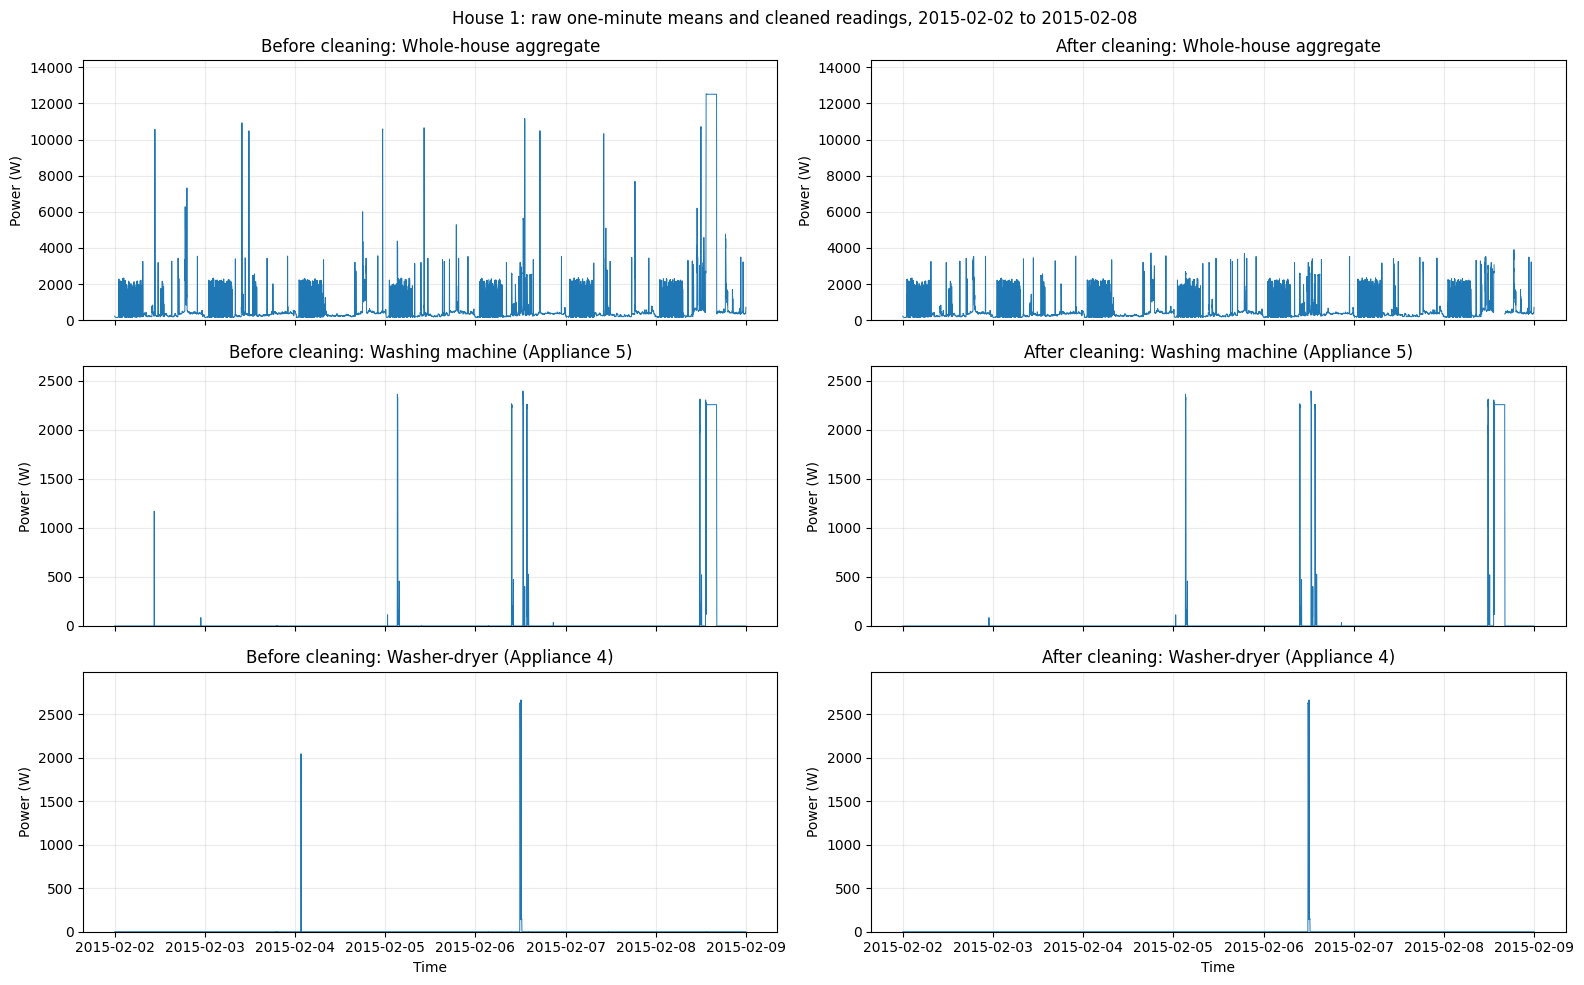

         source_file  input_rows  invalid_timestamp_rows  duplicate_timestamps_removed  rows_after_timestamp_deduplication               start                 end  interval_min_seconds  interval_median_seconds  interval_p95_seconds  interval_max_seconds  gaps_over_60_seconds  raw_missing_values  values_over_4000_watts
RAW_House1_Part1.csv     4377877                       0                        645514                             3732363 2013-10-09 14:06:17 2014-10-01 01:27:07                   1.0                      5.0                  15.0             3594413.0                   780                   0                   19647
RAW_House1_Part2.csv     4140886                       0                             0                             4140886 2014-06-27 21:57:50 2015-07-10 11:56:32                   1.0                      7.0                   8.0              747252.0                  3603             5284083                   21505

Channel gap summary:
   channel  missin

In [3]:
def prefer_later_source(earlier, later):
    """Use later-source minute rows where present, preserving its explicit NaNs."""
    index = earlier.index.union(later.index).sort_values()
    result = earlier.reindex(index)
    later_aligned = later.reindex(index)
    later_minutes = index.isin(later.index)
    result.loc[later_minutes, CHANNELS] = later_aligned.loc[later_minutes, CHANNELS]
    return result

raw_before = prefer_later_source(raw_minute_parts[0], raw_minute_parts[1])
minute_data = prefer_later_source(clean_minute_parts[0], clean_minute_parts[1])
overlap_minutes = len(raw_minute_parts[0].index.intersection(raw_minute_parts[1].index))
complete_index = pd.date_range(minute_data.index.min().floor("min"),
                               minute_data.index.max().floor("min"), freq="1min")
raw_before = raw_before.reindex(complete_index)
minute_data = minute_data.reindex(complete_index)

def long_gap_mask(series, max_short_gap=MAX_FILLED_GAP_MINUTES):
    missing = series.isna()
    run_id = missing.ne(missing.shift(fill_value=False)).cumsum()
    run_length = missing.groupby(run_id).transform("sum")
    return missing & (run_length > max_short_gap)

def fill_short_gaps(series, max_short_gap=MAX_FILLED_GAP_MINUTES):
    missing = series.isna()
    run_id = missing.ne(missing.shift(fill_value=False)).cumsum()
    run_length = missing.groupby(run_id).transform("sum")
    fillable = missing & (run_length <= max_short_gap)
    interpolated = series.interpolate(method="time", limit_area="inside")
    return series.mask(fillable, interpolated)

cleaned = minute_data.copy()
long_gap_counts = {}
for channel in CHANNELS:
    long_gap = long_gap_mask(cleaned[channel])
    cleaned[f"outage_{channel}"] = long_gap
    long_gap_counts[channel] = int(long_gap.sum())
    cleaned[channel] = fill_short_gaps(cleaned[channel])

cleaned.index.name = "Time"
clean_path = OUTPUT_DIR / "house1_cleaned_1min.csv.gz"
cleaned.to_csv(clean_path, compression="gzip", float_format="%.2f")

channel_summary = pd.DataFrame({
    "channel": CHANNELS,
    "missing_minutes_before_fill": [int(minute_data[channel].isna().sum()) for channel in CHANNELS],
    "short_gap_minutes_filled": [int(minute_data[channel].isna().sum() - cleaned[channel].isna().sum()) for channel in CHANNELS],
    "long_outage_minutes_flagged": [long_gap_counts[channel] for channel in CHANNELS],
    "missing_minutes_after_fill": [int(cleaned[channel].isna().sum()) for channel in CHANNELS],
})
channel_summary.to_csv(OUTPUT_DIR / "channel_gap_summary.csv", index=False)

def markdown_table(frame):
    headers = [str(column) for column in frame.columns]
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    for row in frame.itertuples(index=False, name=None):
        values = [str(value) for value in row]
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
plot_channels = [
    ("Aggregate", "Whole-house aggregate"),
    ("Appliance5", "Washing machine (Appliance 5)"),
    ("Appliance4", "Washer-dryer (Appliance 4)"),
]
daily_activity = cleaned[["Appliance4", "Appliance5"]].resample("D").sum().fillna(0)
weekly_activity = daily_activity.sum(axis=1).rolling(7, min_periods=7).sum()
week_end = weekly_activity.idxmax().normalize()
plot_start = week_end - pd.Timedelta(days=6)
plot_end = plot_start + pd.Timedelta(days=7) - pd.Timedelta(minutes=1)
for row, (channel, label) in enumerate(plot_channels):
    axes[row, 0].plot(raw_before.loc[plot_start:plot_end].index,
                      raw_before.loc[plot_start:plot_end, channel], linewidth=0.7)
    axes[row, 0].set_title(f"Before cleaning: {label}")
    axes[row, 1].plot(cleaned.loc[plot_start:plot_end].index,
                      cleaned.loc[plot_start:plot_end, channel], linewidth=0.7)
    axes[row, 1].set_title(f"After cleaning: {label}")
    for axis in axes[row]:
        axis.set_ylabel("Power (W)")
        axis.grid(alpha=0.25)
        upper = max(raw_before.loc[plot_start:plot_end, channel].quantile(0.999),
                    cleaned.loc[plot_start:plot_end, channel].quantile(0.999))
        if pd.notna(upper) and upper > 0:
            axis.set_ylim(0, upper * 1.15)
axes[-1, 0].set_xlabel("Time")
axes[-1, 1].set_xlabel("Time")
fig.suptitle(f"House 1: raw one-minute means and cleaned readings, {plot_start.date()} to {plot_end.date()}")
fig.tight_layout()
plot_path = OUTPUT_DIR / "house1_before_after_cleaning.png"
fig.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

report_lines = [
    "# House 1 raw data quality and cleaning report",
    "",
    "## Inputs and cleaning rules",
    "",
    "Inputs are the existing `RAW_House1_Part1.csv` and `RAW_House1_Part2.csv` files. Input files were not modified.",
    "Within each file, invalid timestamps are dropped, duplicate timestamps keep the last row in file order, and rows are then sorted by timestamp. Minute means are calculated per file; where both parts contain a minute, Part 2 replaces Part 1 for that whole minute, including explicit missing values. Values above 4,000 W are treated as spikes on all channels. Complete internal gaps up to five minutes are time-interpolated; longer missing runs are retained and flagged by channel.",
    "",
    "## Source profile",
    "",
    markdown_table(source_summary),
    "",
    f"The two source parts overlap for {overlap_minutes:,} minute bins. The final one-minute series contains {len(cleaned):,} timestamps from {cleaned.index.min()} through {cleaned.index.max()}.",
    "",
    "## Missing readings and long outages",
    "",
    markdown_table(channel_summary),
    "",
    "## Interpretation and caveats",
    "",
    "House 1 Part 1 is not chronologically ordered and contains repeated timestamps; Part 2 contains explicit NaNs and overlaps Part 1. The source interval statistics and missing counts above describe the observed data rather than assuming a perfectly regular 6–8-second cadence. The official cleaned-data notes specifically describe >4,000 W IAM spikes; applying this threshold to the aggregate as well is a conservative analysis choice and may remove a genuinely unusual high household load. The input data only records active power, and the sensors are not perfectly synchronized.",
    "",
    f"The figure compares raw and cleaned one-minute means over the seven-day period with the greatest combined activity on the washer-dryer and washing machine ({plot_start.date()} to {plot_end.date()}). Plot limits use the 99.9th percentile to keep normal variation visible, so the y-axis may omit the most extreme raw spikes.",
    "",
    "## Outputs",
    "",
    "- `house1_cleaned_1min.csv.gz`: cleaned one-minute power channels plus per-channel long-outage flags.",
    "- `house1_before_after_cleaning.png`: aggregate, washing-machine, and washer-dryer traces before and after cleaning.",
    "- `source_quality_summary.csv`, `channel_quality_by_source.csv`, and `channel_gap_summary.csv`: tabular quality findings.",
]
report_path = OUTPUT_DIR / "data_quality_report.md"
report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")

summary = {
    "combined_minutes": int(len(cleaned)),
    "combined_start": str(cleaned.index.min()),
    "combined_end": str(cleaned.index.max()),
    "part_overlap_minutes": int(overlap_minutes),
    "output_csv": str(clean_path.relative_to(PROJECT_ROOT)),
    "plot": str(plot_path.relative_to(PROJECT_ROOT)),
    "report": str(report_path.relative_to(PROJECT_ROOT)),
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(source_summary.to_string(index=False))
print("\nChannel gap summary:")
print(channel_summary.to_string(index=False))
print(f"\nSaved: {clean_path.relative_to(PROJECT_ROOT)}")
print(f"Saved: {plot_path.relative_to(PROJECT_ROOT)}")
print(f"Saved: {report_path.relative_to(PROJECT_ROOT)}")